In [ ]:
import os
import pandas as pd
from google.colab import files

# Upload kaggle.json here
if not os.path.exists("/root/.kaggle/kaggle.json"):
    files.upload()
    !mkdir -p ~/.kaggle
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json

!pip install -q kaggle

Saving kaggle.json to kaggle.json


In [ ]:
# NIH Dataset (using a pre-resized 224x224 version for speed)
!kaggle datasets download -d khanfashee/nih-chest-x-ray-14-224x224-resized --unzip -p nih_data

# Verify the content after unzipping
!ls -F nih_data/

# Read metadata and filter for specific count
nih_df = pd.read_csv('nih_data/Data_Entry_2017.csv')
nih_sample = nih_df.sample(n=10000, random_state=42)
nih_sample.to_csv('nih_data/subset_metadata.csv', index=False)

Dataset URL: https://www.kaggle.com/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized
License(s): CC0-1.0
100% 2.30G/2.30G [01:48<00:00, 22.7MB/s]

BBox_List_2017_Official_NIH.csv  images-224/	      test_list_NIH.txt
Data_Entry_2017.csv		 pretrained_model.h5  train_val_list_NIH.txt


In [ ]:
import pandas as pd
import os

# 1. Sabse pehle labels filter karein
# NIH mein 'Pneumonia' multi-label ho sakta hai (e.g., 'Pneumonia|Infiltration')
positives = nih_df[nih_df['Finding Labels'].str.contains('Pneumonia')]
negatives = nih_df[nih_df['Finding Labels'] == 'No Finding']

# 2. Calculation for 1:3 Ratio
n_pos = len(positives)
n_neg = n_pos * 3

# 3. Randomly sample the negatives to match the ratio
neg_sample = negatives.sample(n=n_neg, random_state=42)

# 4. Combine both to create the final hybrid subset
nih_hybrid_df = pd.concat([positives, neg_sample])

# 5. Shuffle the dataset (training ke liye zaroori hai)
nih_hybrid_df = nih_hybrid_df.sample(frac=1, random_state=42).reset_index(drop=True)

# 6. Binary label column for your project (1 = Pneumonia, 0 = Normal)
nih_hybrid_df['target'] = nih_hybrid_df['Finding Labels'].apply(lambda x: 1 if 'Pneumonia' in x else 0)

print(f"✅ Subset Created Successfully!")
print(f"Total Images: {len(nih_hybrid_df)}")
print(f"Pneumonia Cases (1): {n_pos}")
print(f"Normal Cases (3):    {n_neg}")


✅ Subset Created Successfully!
Total Images: 5412
Pneumonia Cases (1): 1353
Normal Cases (3):    4059


In [ ]:
nih_hybrid_df.shape

(5412, 13)

In [ ]:
nih_df.shape


(112120, 12)

In [ ]:
nih_df=nih_hybrid_df
nih_df.sample(6)

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11,target
669,00027023_002.png,No Finding,2,27023,015Y,M,PA,2392,2612,0.143000,0.143000,NaN,0
475,00025583_004.png,No Finding,4,25583,048Y,M,AP,3056,2544,0.139000,0.139000,NaN,0
2575,00021374_025.png,No Finding,25,21374,081Y,M,PA,2992,2991,0.143000,0.143000,NaN,0
4933,00010092_003.png,Atelectasis|Nodule|Pneumonia,3,10092,047Y,F,PA,2992,2991,0.143000,0.143000,NaN,1
4524,00015539_000.png,No Finding,0,15539,046Y,F,PA,2992,2991,0.143000,0.143000,NaN,0
2101,00011029_001.png,No Finding,1,11029,066Y,F,PA,2021,2021,0.194311,0.194311,NaN,0


In [ ]:
nih_df.describe()


,Follow-up #,Patient ID,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11,target
count,5412.000000,5412.000000,5412.000000,5412.000000,5412.000000,5412.000000,0.0,5412.000000
mean,8.145972,13947.538433,2639.186992,2487.127125,0.155774,0.155774,NaN,0.250000
std,14.990693,8347.170706,339.554079,402.376657,0.015985,0.015985,NaN,0.433053
min,0.000000,13.000000,1301.000000,1433.000000,0.115000,0.115000,NaN,0.000000
25%,0.000000,6932.000000,2500.000000,2048.000000,0.143000,0.143000,NaN,0.000000
50%,2.000000,13671.500000,2500.000000,2532.500000,0.143000,0.143000,NaN,0.000000
75%,9.000000,20073.750000,2992.000000,2991.000000,0.168000,0.168000,NaN,0.250000
max,157.000000,30801.000000,3056.000000,3056.000000,0.194314,0.194314,NaN,1.000000


✅ FINAL SUBSET SUMMARY
Total Images: 5412

📊 CLASS DISTRIBUTION
   - Normal (3x): 4059 images (75.0%)
   - Pneumonia (1x): 1353 images (25.0%)

🖼️ GENERATING SAMPLE GRID...


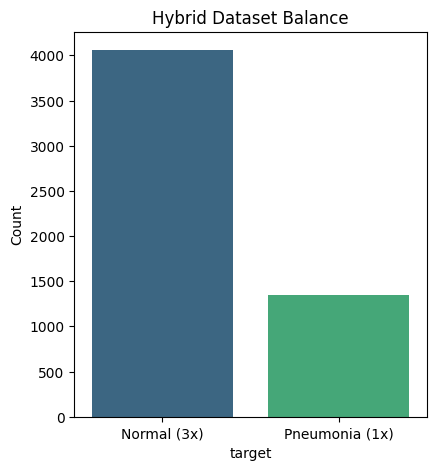

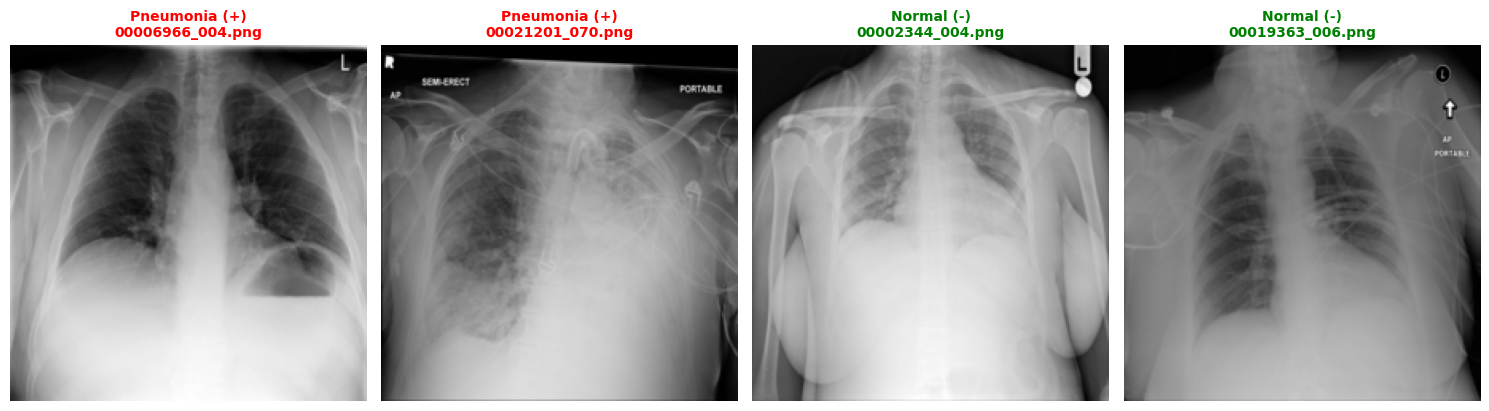

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import os

# --- 1. Print Total Images ---
total_images = len(nih_df)
print(f"✅ FINAL SUBSET SUMMARY")
print(f"{'='*30}")
print(f"Total Images: {total_images}")

# --- 2. Class Distribution ---
dist = nih_df['target'].value_counts()
labels = {0: 'Normal (3x)', 1: 'Pneumonia (1x)'}

print(f"\n📊 CLASS DISTRIBUTION")
for k, v in dist.items():
    print(f"   - {labels[k]}: {v} images ({v/total_images*100:.1f}%)")

# Visualization of Distribution
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
sns.barplot(x=dist.index.map(labels), y=dist.values, hue=dist.index, palette='viridis', legend=False)
plt.title('Hybrid Dataset Balance')
plt.ylabel('Count')

# --- 3. Sample Images ---
# Path setup
img_folder = 'nih_data/images-224/images-224'

def get_samples(df, n=2):
    p_samples = df[df['target'] == 1].head(n)
    n_samples = df[df['target'] == 0].head(n)
    return pd.concat([p_samples, n_samples])

samples = get_samples(nih_df, n=2)

print(f"\n🖼️ GENERATING SAMPLE GRID...")
fig = plt.figure(figsize=(15, 8))
for i, (idx, row) in enumerate(samples.iterrows()):
    img_path = os.path.join(img_folder, row['Image Index'])
    try:
        img = Image.open(img_path)
        plt.subplot(1, 4, i + 1)
        plt.imshow(img, cmap='gray')

        # Formatting titles
        title_text = "Pneumonia (+)" if row['target'] == 1 else "Normal (-)"
        title_color = 'red' if row['target'] == 1 else 'green'
        plt.title(f"{title_text}\n{row['Image Index']}", color=title_color, fontsize=10, fontweight='bold')
        plt.axis('off')
    except Exception as e:
        print(f"Error loading {row['Image Index']}: {e}")

plt.tight_layout()
plt.show()

In [ ]:
import os
from PIL import Image

# --- 1. Label Mapping (Pneumonia -> 1, Normal -> 0) ---
# We keep only rows that are strictly 'No Finding' or contain 'Pneumonia'
nih_df = nih_df[(nih_df['Finding Labels'].str.contains('Pneumonia')) |
                (nih_df['Finding Labels'] == 'No Finding')].copy()

nih_df['target'] = nih_df['Finding Labels'].apply(lambda x: 1 if 'Pneumonia' in x else 0)

# --- 2. Remove Missing/Null Data ---
initial_count = len(nih_df)
nih_df = nih_df.dropna(subset=['Image Index', 'Finding Labels'])

# --- 3. Broken Image Check ---
# We verify if the file exists and can actually be opened by PIL
img_folder = 'nih_data/images-224/images-224'
valid_indices = []

print("🔍 Scrubbing data for broken images...")
for idx, row in nih_df.iterrows():
    img_path = os.path.join(img_folder, row['Image Index'])
    if os.path.exists(img_path):
        try:
            # We don't load the whole pixel array (slow), just verify the header
            with Image.open(img_path) as img:
                img.verify()
            valid_indices.append(idx)
        except Exception:
            print(f"Skipping broken image: {row['Image Index']}")
    else:
        continue

# Apply the filter
nih_df = nih_df.loc[valid_indices].reset_index(drop=True)

# --- 4. Final Verification ---
print(f"\n✅ DATA CLEANING COMPLETE")
print(f"{'='*30}")
print(f"Initial Images: {initial_count}")
print(f"Cleaned Images: {len(nih_df)}")
print(f"Removed:        {initial_count - len(nih_df)} (Broken/Missing)")
print(f"Pneumonia (1):  {nih_df['target'].sum()}")
print(f"Normal (0):     {len(nih_df) - nih_df['target'].sum()}")

🔍 Scrubbing data for broken images...

✅ DATA CLEANING COMPLETE
Initial Images: 5412
Cleaned Images: 5412
Removed:        0 (Broken/Missing)
Pneumonia (1):  1353
Normal (0):     4059


CHEXERT

In [ ]:
# 1. Download CheXpert (Small version: 224x224)
!kaggle datasets download -d mimsadiislam/chexpert --unzip -p chexpert_data

# 2. Read Metadata
# CheXpert has separate train/valid files, but we'll sample from 'train.csv' for your 10k pool
chex_df = pd.read_csv('chexpert_data/CheXpert-v1.0-small/train.csv')

# 3. Handle CheXpert Labels
# In CheXpert, 1.0 is Positive, 0.0 is Negative, and -1.0 is 'Uncertain'
# We focus on Pneumonia and treat Uncertain as Negative to be conservative
chex_df['target'] = chex_df['Pneumonia'].apply(lambda x: 1 if x == 1.0 else 0)





print(f"✅ CheXpert Subset Created!")
print(f"Total Images: {len(chex_df)}")


Dataset URL: https://www.kaggle.com/datasets/mimsadiislam/chexpert
License(s): unknown
100% 10.7G/10.7G [08:58<00:00, 21.4MB/s]

✅ CheXpert Subset Created!
Total Images: 223414


In [ ]:
# Adjust paths to match your Colab directory
base_path = 'chexpert_data/'
valid_chex_indices = []

print("🔍 Verifying CheXpert image paths...")
for idx, row in chex_df.iterrows():
    full_path = os.path.join(base_path, row['Path'])
    if os.path.exists(full_path):
        valid_chex_indices.append(idx)

chex_subset_df = chex_df.loc[valid_chex_indices].reset_index(drop=True)

print(f"✅ Cleaned CheXpert Images: {len(chex_subset_df)}")

🔍 Verifying CheXpert image paths...
✅ Cleaned CheXpert Images: 223414


In [ ]:
import pandas as pd
import os
from PIL import Image # Import Image for validation

# 1. Pehle breakdown dekhte hain: Pneumonia cases mein kitne Lateral hain
pneumonia_all = chex_df[chex_df['Pneumonia'] == 1.0]
view_breakdown = pneumonia_all['Frontal/Lateral'].value_counts()

print("📊 PNEUMONIA VIEW BREAKDOWN (Before Filtering):")
print(view_breakdown)
print("-" * 30)

# 2. Filter for Frontal Only
# (NIH ke saath align karne ke liye sirf Frontal views zaroori hain)
chex_frontal_df = chex_df[chex_df['Frontal/Lateral'] == 'Frontal'].copy()

# 3. Separate the classes from the Frontal pool
chex_positives = chex_frontal_df[chex_frontal_df['Pneumonia'] == 1.0]
chex_negatives = chex_frontal_df[chex_frontal_df['Pneumonia'] != 1.0]

# 4. Sampling Logic
n_pos = len(chex_positives)
n_neg_requested = 5000 # Aapki request: 5k Normal images
n_neg = min(len(chex_negatives), n_neg_requested)

chex_neg_sample = chex_negatives.sample(n=n_neg, random_state=42)

# 5. Combine and create final Target column
chex_final_df = pd.concat([chex_positives, chex_neg_sample]).sample(frac=1, random_state=42).reset_index(drop=True)
chex_final_df['target'] = (chex_final_df['Pneumonia'] == 1.0).astype(int)

# --- NEW: Image Scrubbing for CheXpert ---
base_chex_img_dir = 'chexpert_data/'
initial_count_chex = len(chex_final_df)
valid_chex_indices = []

print(f"\n🔍 Scrubbing CheXpert data for broken/missing images ({initial_count_chex} initial images)...")
for idx, row in chex_final_df.iterrows():
    img_path = os.path.join(base_chex_img_dir, row['Path'])
    if os.path.exists(img_path):
        try:
            with Image.open(img_path) as img:
                img.verify() # Verify image integrity
            valid_chex_indices.append(idx)
        except Exception:
            # print(f"Skipping broken CheXpert image: {row['Path']}") # Uncomment for detailed logging
            pass
    else:
        # print(f"Skipping missing CheXpert image: {row['Path']}") # Uncomment for detailed logging
        pass

chex_final_df = chex_final_df.loc[valid_chex_indices].reset_index(drop=True)
# ----------------------------------------

# Update chex_df for future cells
chex_df = chex_final_df

print(f"\n✅ CheXpert Frontal-Only Subset Created!")
print(f"Total Images (After Scrubbing): {len(chex_df)}")
print(f"Pneumonia (Frontal): {chex_df['target'].sum()}")
print(f"Normal (Frontal):    {len(chex_df) - chex_df['target'].sum()}")
print(f"Removed during scrubbing: {initial_count_chex - len(chex_df)} (Broken/Missing)")


📊 PNEUMONIA VIEW BREAKDOWN (Before Filtering):
Frontal/Lateral
Frontal    4675
Lateral    1364
Name: count, dtype: int64
------------------------------

🔍 Scrubbing CheXpert data for broken/missing images (9675 initial images)...

✅ CheXpert Frontal-Only Subset Created!
Total Images (After Scrubbing): 9675
Pneumonia (Frontal): 4675
Normal (Frontal):    5000
Removed during scrubbing: 0 (Broken/Missing)



📊 CHEXPERT DISTRIBUTION
   - Normal:    5000 (51.7%)
   - Pneumonia: 4675 (48.3%)


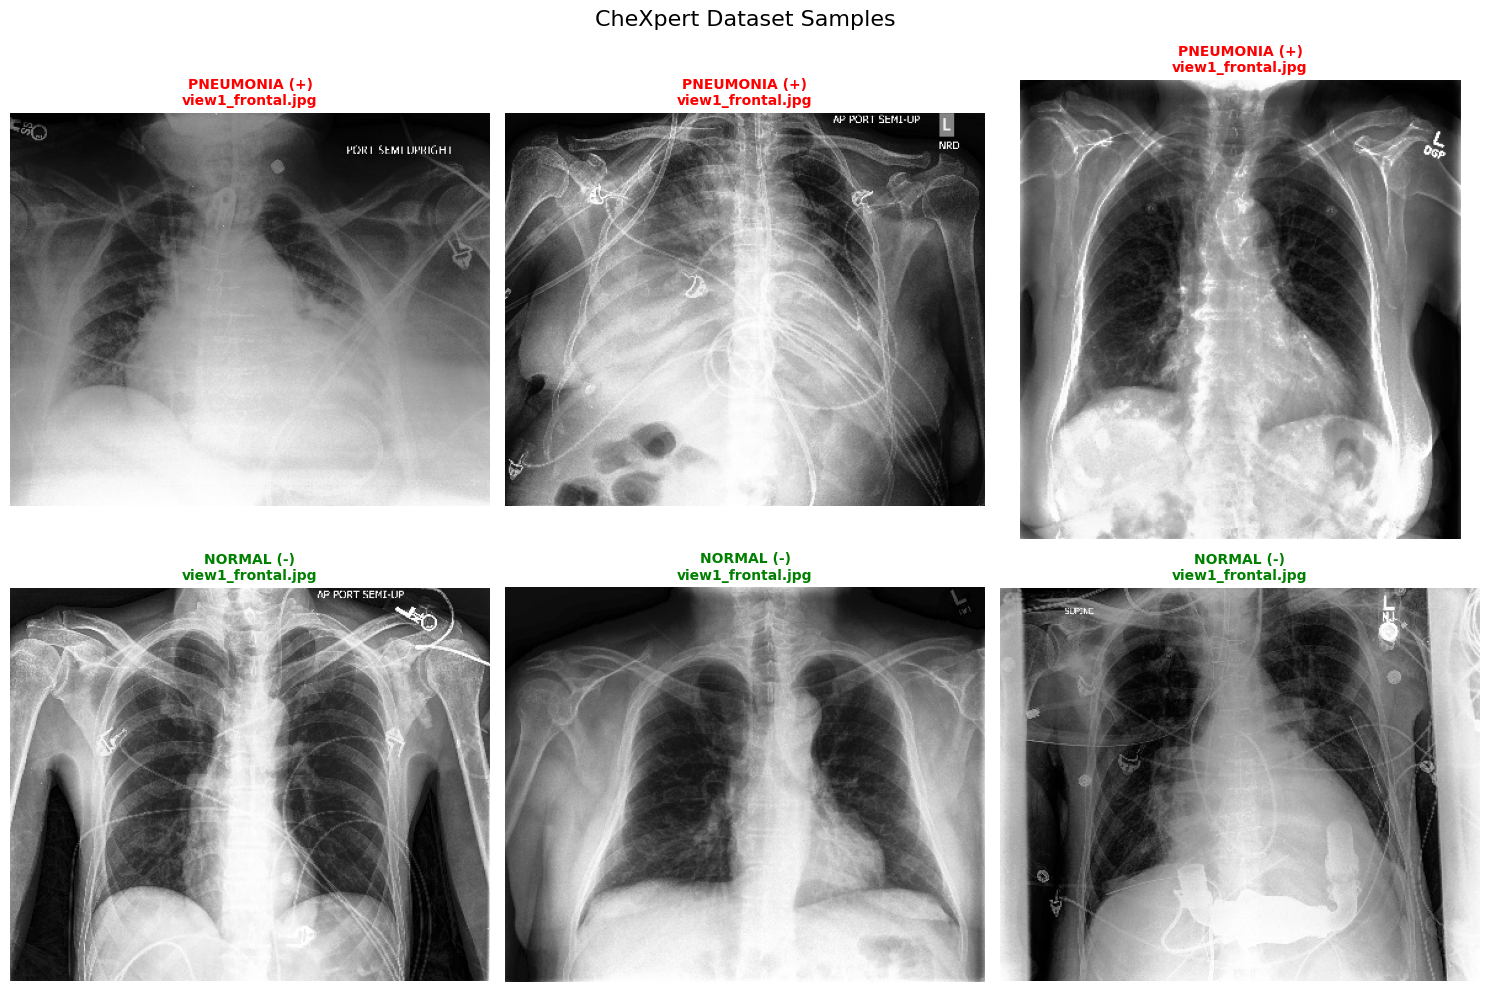

In [ ]:
# Print Class Distribution for CheXpert
dist_chex = chex_df['target'].value_counts()
print(f"\n📊 CHEXPERT DISTRIBUTION")
print(f"   - Normal:    {dist_chex[0]} ({dist_chex[0]/len(chex_df)*100:.1f}%)")
print(f"   - Pneumonia: {dist_chex[1]} ({dist_chex[1]/len(chex_df)*100:.1f}%)")

import matplotlib.pyplot as plt
from PIL import Image
import os

def show_chex_grid(df, base_path, n_per_class=3):
    # 1. Grab n samples from each class
    pos_samples = df[df['target'] == 1].head(n_per_class)
    neg_samples = df[df['target'] == 0].head(n_per_class)
    display_df = pd.concat([pos_samples, neg_samples])

    # 2. Setup the Plot (2 rows, n columns)
    fig, axes = plt.subplots(2, n_per_class, figsize=(15, 10))
    axes = axes.flatten()

    for i, (idx, row) in enumerate(display_df.iterrows()):
        img_path = os.path.join(base_path, row['Path'])
        try:
            img = Image.open(img_path)
            axes[i].imshow(img, cmap='gray')

            # Labeling logic
            label_name = "PNEUMONIA (+)" if row['target'] == 1 else "NORMAL (-)"
            color = 'red' if row['target'] == 1 else 'green'

            # Extract filename from path for the title
            fname = row['Path'].split('/')[-1]
            axes[i].set_title(f"{label_name}\n{fname}", color=color, fontsize=10, fontweight='bold')
            axes[i].axis('off')
        except Exception as e:
            print(f"Error loading {row['Path']}: {e}")

    plt.tight_layout()
    plt.suptitle("CheXpert Dataset Samples", fontsize=16, y=1.02)
    plt.show()

# Run it!
# Ensure 'base_path' is where your CheXpert-v1.0-small folder lives
show_chex_grid(chex_final_df, 'chexpert_data/', n_per_class=3)

In [ ]:
chex_df.shape


(9675, 20)

In [ ]:
chex_df.head()

,Path,Sex,Age,Frontal/Lateral,AP/PA,No Finding,Enlarged Cardiomediastinum,Cardiomegaly,Lung Opacity,Lung Lesion,Edema,Consolidation,Pneumonia,Atelectasis,Pneumothorax,Pleural Effusion,Pleural Other,Fracture,Support Devices,target
0,CheXpert-v1.0-small/train/patient59320/study1/...,Male,57,Frontal,AP,NaN,NaN,NaN,-1.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,1.0,0
1,CheXpert-v1.0-small/train/patient05702/study61...,Female,61,Frontal,AP,NaN,NaN,1.0,1.0,NaN,1.0,NaN,1.0,1.0,NaN,NaN,NaN,NaN,1.0,1
2,CheXpert-v1.0-small/train/patient12994/study2/...,Female,75,Frontal,AP,NaN,NaN,NaN,1.0,NaN,NaN,-1.0,1.0,-1.0,NaN,1.0,NaN,NaN,1.0,1
3,CheXpert-v1.0-small/train/patient05398/study1/...,Male,67,Frontal,PA,NaN,NaN,NaN,1.0,NaN,-1.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0
4,CheXpert-v1.0-small/train/patient28746/study8/...,Male,62,Frontal,AP,NaN,NaN,1.0,1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,1.0,0


In [ ]:
chex_df.describe()

,Age,No Finding,Enlarged Cardiomediastinum,Cardiomegaly,Lung Opacity,Lung Lesion,Edema,Consolidation,Pneumonia,Atelectasis,Pneumothorax,Pleural Effusion,Pleural Other,Fracture,Support Devices,target
count,9675.000000,447.0,1567.000000,1633.000000,6130.000000,613.000000,3735.000000,3011.000000,5156.000000,2725.000000,2426.000000,4907.000000,276.000000,375.000000,4629.000000,9675.000000
mean,61.420052,1.0,-0.059349,0.454991,0.873573,0.696574,0.441232,0.018931,0.824476,-0.038899,0.211871,0.620746,0.235507,0.738667,0.938000,0.483204
std,18.287040,0.0,0.738246,0.778440,0.448528,0.666131,0.797836,0.852185,0.556097,0.992608,0.497871,0.642180,0.925776,0.518093,0.271526,0.499744
min,18.000000,1.0,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,0.000000
25%,50.000000,1.0,-1.000000,0.000000,1.000000,1.000000,0.000000,-1.000000,1.000000,-1.000000,0.000000,0.000000,-1.000000,1.000000,1.000000,0.000000
50%,63.000000,1.0,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,-1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000
75%,76.000000,1.0,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
max,90.000000,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
# 'Pneumonia' == 1.0 filters for the disease, then we count the 'Frontal/Lateral' types
print(chex_df[chex_df['Pneumonia'] == 1.0]['Frontal/Lateral'].value_counts())



Frontal/Lateral
Frontal    4675
Name: count, dtype: int64


📊 CHEXPERT CLASS IMBALANCE REPORT
Total Frontal Images: 9675
Pneumonia (1):        4675 images (48.32%)
Normal/Other (0):     5000 images (51.68%)


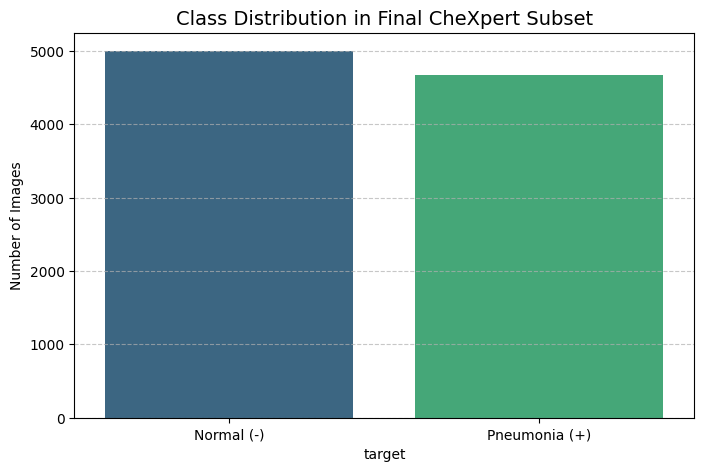

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate Counts
dist = chex_df['target'].value_counts()
total = len(chex_df)

# 2. Print Summary
print(f"📊 CHEXPERT CLASS IMBALANCE REPORT")
print(f"{'='*35}")
print(f"Total Frontal Images: {total}")
print(f"Pneumonia (1):        {dist[1]} images ({dist[1]/total*100:.2f}%)")
print(f"Normal/Other (0):     {dist[0]} images ({dist[0]/total*100:.2f}%)")
print(f"{'='*35}")

# 3. Visualization
plt.figure(figsize=(8, 5))
labels = {1: 'Pneumonia (+)', 0: 'Normal (-)'}
sns.barplot(x=dist.index.map(labels), y=dist.values, hue=dist.index, palette='viridis', legend=False)

plt.title('Class Distribution in Final CheXpert Subset', fontsize=14)
plt.ylabel('Number of Images')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

RSNA

In [ ]:
# 1. Install pydicom (DICOM images read karne ke liye)
!pip install -q pydicom

import os
import pandas as pd
import pydicom
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# 2. Download from Competition
!mkdir -p rsna_data
!kaggle competitions download -c rsna-pneumonia-detection-challenge -p rsna_data

# 3. Unzip
!unzip -q rsna_data/rsna-pneumonia-detection-challenge.zip -d rsna_data

# 4. Load Labels
rsna_df = pd.read_csv('rsna_data/stage_2_train_labels.csv')
# Sirf Pneumonia cases filter karo alignment (Phase 4) ke liye
rsna_boxes = rsna_df[rsna_df['Target'] == 1].copy()

print(f"✅ RSNA Data Ready!")
print(f"Total Labels: {len(rsna_df)}")
print(f"Pneumonia Boxes: {len(rsna_boxes)}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 82.8 MB/s eta 0:00:00
100% 3.66G/3.66G [03:08<00:00, 20.9MB/s]

✅ RSNA Data Ready!
Total Labels: 30227
Pneumonia Boxes: 9555


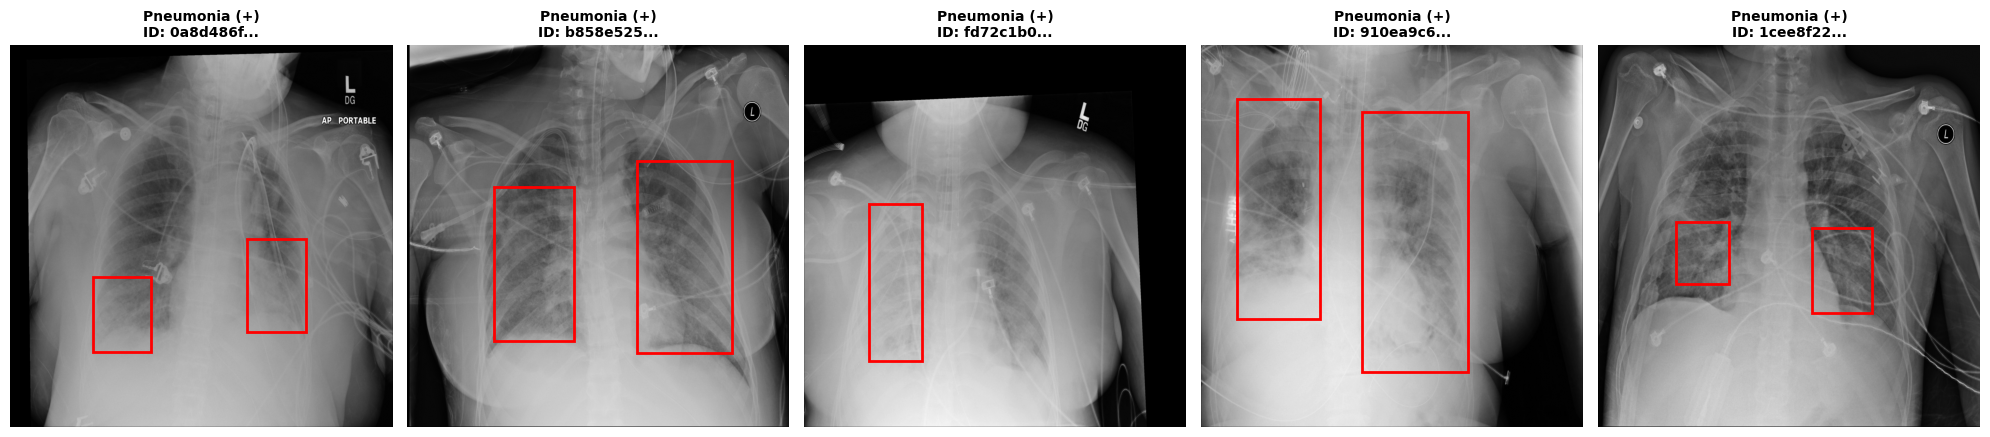

In [ ]:
import pydicom
import matplotlib.patches as patches
import numpy as np

def plot_rsna_samples(df, img_dir, n=5):
    # 1. Get 5 unique pneumonia patient IDs
    unique_pids = df['patientId'].unique()
    sample_pids = np.random.choice(unique_pids, n, replace=False)

    # 2. Setup Plot
    fig, axes = plt.subplots(1, n, figsize=(20, 6))

    for i, pid in enumerate(sample_pids):
        # Path to DICOM file
        dcm_path = os.path.join(img_dir, f"{pid}.dcm")

        # Read DICOM and get pixel data
        ds = pydicom.dcmread(dcm_path)
        img = ds.pixel_array

        # Plot Image
        axes[i].imshow(img, cmap='gray')

        # Find all boxes for this specific patient (one patient can have >1 box)
        patient_boxes = df[df['patientId'] == pid]

        for _, row in patient_boxes.iterrows():
            # Draw the Bounding Box
            rect = patches.Rectangle(
                (row['x'], row['y']), row['width'], row['height'],
                linewidth=2, edgecolor='red', facecolor='none'
            )
            axes[i].add_patch(rect)

        axes[i].set_title(f"Pneumonia (+)\nID: {pid[:8]}...", fontsize=10, fontweight='bold')
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

# 3. Execute (Images are in 'stage_2_train_images' folder)
img_folder = 'rsna_data/stage_2_train_images'
plot_rsna_samples(rsna_boxes, img_folder, n=5)

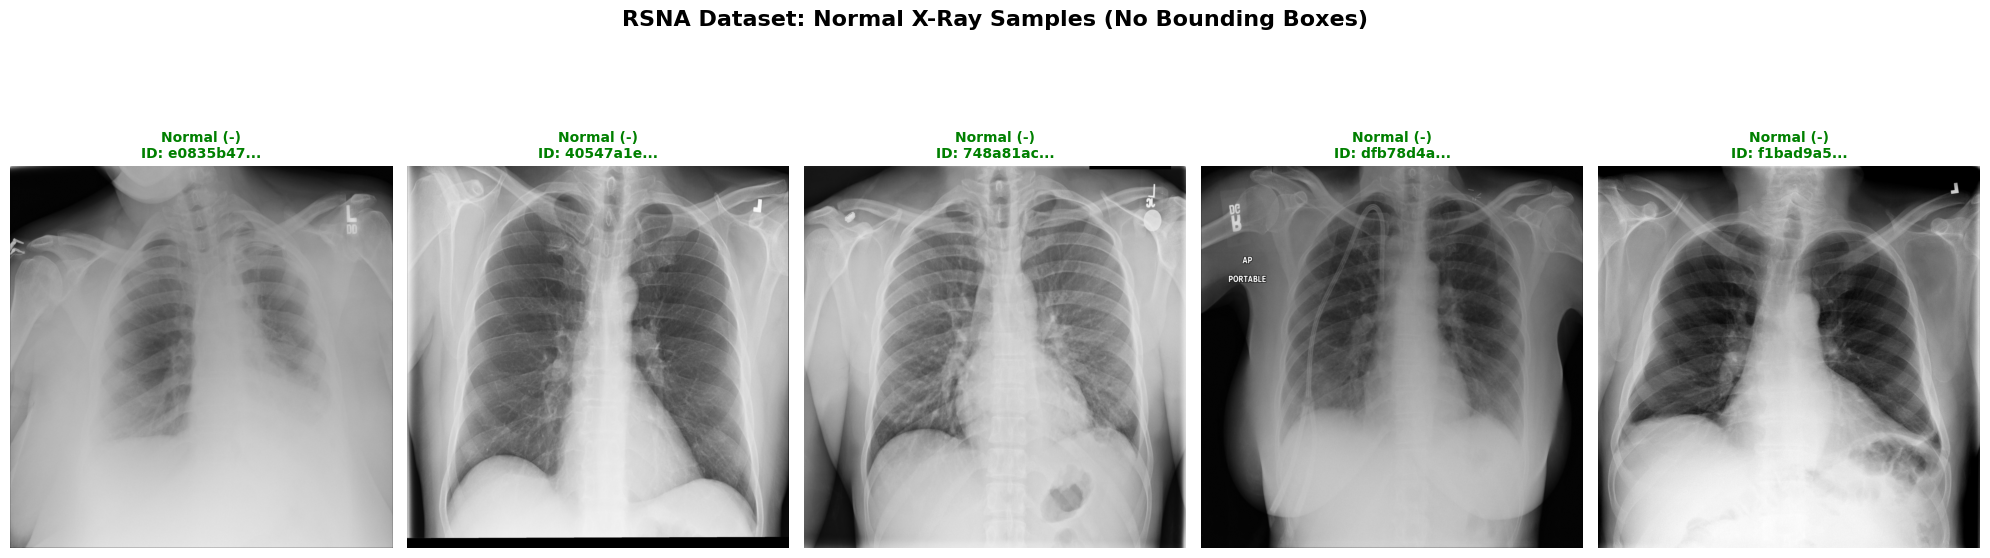

In [ ]:
import pydicom
import matplotlib.pyplot as plt
import numpy as np
import os

def plot_rsna_normal_samples(df, img_dir, n=5):
    # 1. Sirf wo patients filter karein jinka Target 0 hai (Normal)
    normal_pids = df[df['Target'] == 0]['patientId'].unique()

    # Randomly pick n normal patients
    sample_pids = np.random.choice(normal_pids, n, replace=False)

    # 2. Setup Plot
    fig, axes = plt.subplots(1, n, figsize=(20, 6))

    for i, pid in enumerate(sample_pids):
        # Path to DICOM file
        dcm_path = os.path.join(img_dir, f"{pid}.dcm")

        try:
            # Read DICOM and get pixel data
            ds = pydicom.dcmread(dcm_path)
            img = ds.pixel_array

            # Plot Image
            axes[i].imshow(img, cmap='gray')
            axes[i].set_title(f"Normal (-)\nID: {pid[:8]}...", fontsize=10, fontweight='bold', color='green')
            axes[i].axis('off')
        except Exception as e:
            axes[i].set_title(f"Error loading ID")
            axes[i].axis('off')

    plt.suptitle("RSNA Dataset: Normal X-Ray Samples (No Bounding Boxes)", fontsize=16, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

# 3. Execute
img_folder = 'rsna_data/stage_2_train_images'
# Note: Yahan 'rsna_df' use karein kyunki 'rsna_boxes' mein normal labels nahi hote
plot_rsna_normal_samples(rsna_df, img_folder, n=5)

✅ RSNA Balanced Subset Created
Total Unique Patients: 13012
Infected (1):          6012 patients
Normal (0):            7000 patients


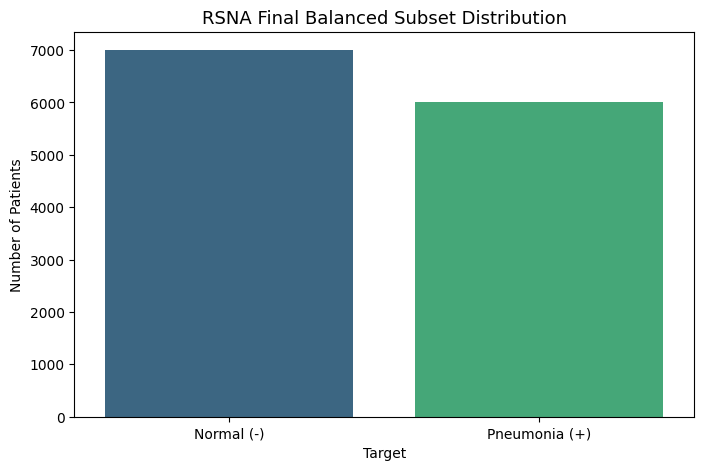

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Pehle unique patients ki list banayein labels ke saath
# (Ek patient ki multiple rows ho sakti hain, isliye groupby zaroori hai)
rsna_unique = rsna_df.groupby('patientId')['Target'].first().reset_index()

# 2. Classes ko alag karein
rsna_pos_patients = rsna_unique[rsna_unique['Target'] == 1]
rsna_neg_patients = rsna_unique[rsna_unique['Target'] == 0]

# 3. Normal cases se exactly 7,000 sample karein
n_normal_to_keep = 7000
rsna_neg_subset = rsna_neg_patients.sample(n=n_normal_to_keep, random_state=42)

# 4. Dono ko merge karein (All Positives + 7k Negatives)
rsna_final_patients = pd.concat([rsna_pos_patients, rsna_neg_subset])

# 5. Master rsna_df se sirf in patients ka data nikalain
rsna_df = rsna_df[rsna_df['patientId'].isin(rsna_final_patients['patientId'])].reset_index(drop=True)

# --- Verification & Print ---
dist = rsna_df.groupby('patientId')['Target'].first().value_counts()
total_pts = len(rsna_df['patientId'].unique())

print(f"✅ RSNA Balanced Subset Created")
print(f"{'='*35}")
print(f"Total Unique Patients: {total_pts}")
print(f"Infected (1):          {dist[1]} patients")
print(f"Normal (0):            {dist[0]} patients")
print(f"{'='*35}")

# Visualization
plt.figure(figsize=(8, 5))
labels = {1: 'Pneumonia (+)', 0: 'Normal (-)'}
sns.barplot(x=dist.index.map(labels), y=dist.values, hue=dist.index, palette='viridis', legend=False)
plt.title('RSNA Final Balanced Subset Distribution', fontsize=13)
plt.ylabel('Number of Patients')
plt.show()

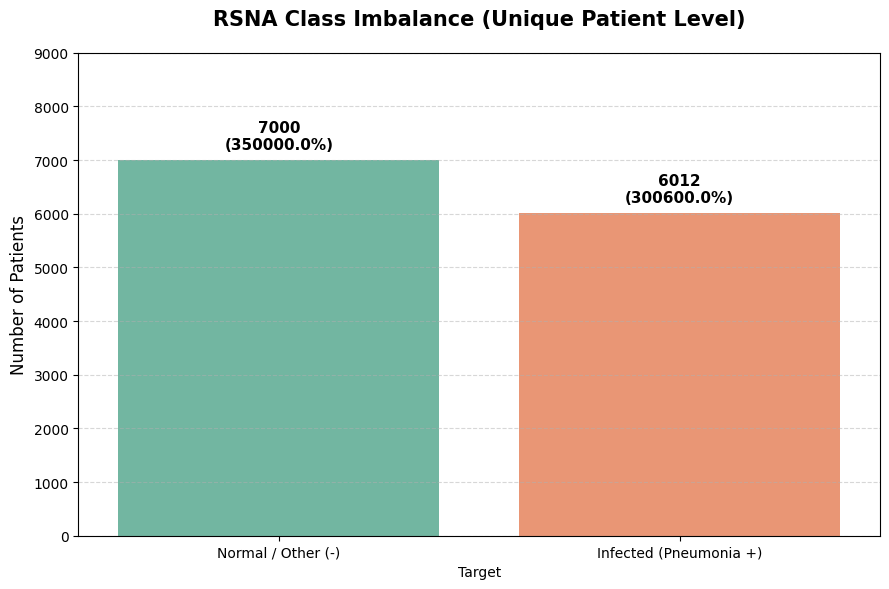

✅ Total Unique Patients: 2
✅ Normal Cases (0):      7000 (350000.0%)
✅ Infected Cases (1):    6012 (300600.0%)


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Unique Patients ka status nikalna (1 patient = 1 label)
# rsna_df mein se unique patientId pakrain aur unka Target check karein
unique_rsna_dist = rsna_df.groupby('patientId')['Target'].first().value_counts()

# 2. Labels setup
labels = {0: 'Normal / Other (-)', 1: 'Infected (Pneumonia +)'}
total_patients = len(unique_rsna_dist)

# 3. Visualization
plt.figure(figsize=(9, 6))
sns.barplot(x=unique_rsna_dist.index.map(labels),
            y=unique_rsna_dist.values,
            hue=unique_rsna_dist.index,
            palette='Set2',
            legend=False)

# Bars ke upar exact count aur percentage likhna
for i, count in enumerate(unique_rsna_dist.values):
    percentage = (count / total_patients) * 100
    plt.text(i, count + 150, f'{count}\n({percentage:.1f}%)',
             ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.title('RSNA Class Imbalance (Unique Patient Level)', fontsize=15, fontweight='bold', pad=20)
plt.ylabel('Number of Patients', fontsize=12)
plt.ylim(0, max(unique_rsna_dist.values) + 2000) # Thori space upar labels ke liye
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# 4. Final Text Print
print(f"✅ Total Unique Patients: {total_patients}")
print(f"✅ Normal Cases (0):      {unique_rsna_dist[0]} ({unique_rsna_dist[0]/total_patients*100:.1f}%)")
print(f"✅ Infected Cases (1):    {unique_rsna_dist[1]} ({unique_rsna_dist[1]/total_patients*100:.1f}%)")

In [ ]:
import torch
from torch.utils.data import Dataset
from PIL import Image
import pydicom
import os
import numpy as np
import pandas as pd
from torchvision import transforms

class ChestXRayDataset(Dataset):
    def __init__(self, df, img_dir, transform=None, is_rsna=False):
        self.df = df
        self.img_dir = img_dir
        self.transform = transform
        self.is_rsna = is_rsna

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        # 1. Path Setup
        if self.is_rsna:
            img_path = os.path.join(self.img_dir, f"{row['patientId']}.dcm")
        elif 'Image Index' in row:
            img_path = os.path.join(self.img_dir, row['Image Index'])
        else:
            img_path = os.path.join(self.img_dir, row['Path'])

        # 2. Image Loading
        try:
            if self.is_rsna:
                ds = pydicom.dcmread(img_path)
                img_array = ds.pixel_array
                image = Image.fromarray(img_array).convert("RGB")
            else:
                image = Image.open(img_path).convert("RGB")
        except Exception as e:
            print(f"Error loading {img_path}: {e}")
            image = Image.new('RGB', (224, 224), color=0)

        # 3. Apply Preprocessing
        if self.transform:
            image = self.transform(image)

        # 4. Handle Mask (For RSNA only)
        mask = torch.zeros((1, 224, 224), dtype=torch.float32)
        if self.is_rsna and row['Target'] == 1:
            # Only if pneumonia is present (Target == 1), create the mask
            scale = 224 / 1024 # Assuming original DICOM is 1024x1024
            x, y, w, h = row['x'], row['y'], row['width'], row['height']

            # Ensure coordinates are within image bounds
            x1, y1 = int(max(0, x * scale)), int(max(0, y * scale))
            x2, y2 = int(min(224, (x + w) * scale)), int(min(224, (y + h) * scale))

            mask[:, y1:y2, x1:x2] = 1.0

        # 5. Target Label
        label = torch.tensor(row['target'] if 'target' in row else row['Target'], dtype=torch.long)

        return image, label, mask

print("✅ Updated ChestXRayDataset ready to return masks!")


preprocess_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandAugment(num_ops=2, magnitude=9), # <--- Add this
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

✅ Updated ChestXRayDataset ready to return masks!


In [ ]:
from torch.utils.data import DataLoader

# --- 1. Path Configuration ---
# Apne folders ke mutabiq inhein verify karlein
nih_img_dir = 'nih_data/images-224/images-224'
chex_img_dir = 'chexpert_data/'  # CheXpert paths CSV ke andar already detailed hain
rsna_img_dir = 'rsna_data/stage_2_train_images'

# --- 2. Initialize Datasets ---

# NIH (Source Hospital)
nih_dataset = ChestXRayDataset(nih_df, nih_img_dir, transform=preprocess_transform)

# CheXpert (Target Hospital - Cross Hospital Test)
chexpert_dataset = ChestXRayDataset(chex_df, chex_img_dir, transform=preprocess_transform)

# RSNA (Clinical Alignment - Ground Truth Boxes)
rsna_dataset = ChestXRayDataset(rsna_df, rsna_img_dir, transform=preprocess_transform, is_rsna=True)

print(f"✅ NIH Dataset initialized:      {len(nih_dataset)} images")
print(f"✅ CheXpert Dataset initialized: {len(chexpert_dataset)} images")
print(f"✅ RSNA Dataset initialized:     {len(rsna_dataset)} images")

✅ NIH Dataset initialized:      5412 images
✅ CheXpert Dataset initialized: 9675 images
✅ RSNA Dataset initialized:     16555 images


Data Loaders

In [ ]:
from torch.utils.data import DataLoader

# --- 1. Configuration ---
BATCH_SIZE = 32
NUM_WORKERS = 2  # Background mein data load karne ke liye cores

# --- 2. Create DataLoaders ---

# NIH (Source Hospital - Training ke liye)
# Isay shuffle karna zaroori hai
nih_loader = DataLoader(
    nih_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)

# CheXpert (Target Hospital - Testing ke liye)
# Isay shuffle karne ki zaroori nahi
chex_loader = DataLoader(
    chexpert_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

# RSNA (Clinical Alignment - Alignment Phase ke liye)
rsna_loader = DataLoader(
    rsna_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

print(f"✅ DataLoaders Ready!")
print(f"📦 NIH Batches:      {len(nih_loader)}")
print(f"📦 CheXpert Batches: {len(chex_loader)}")
print(f"📦 RSNA Batches:     {len(rsna_loader)}")

# --- 3. Simple Sanity Check ---
# Check if one batch loads correctly
images, labels,_ = next(iter(nih_loader))
print(f"\n🔍 Sanity Check (NIH Batch):")
print(f"Image Batch Shape: {images.shape}") # Expecting [32, 3, 224, 224]
print(f"Label Batch Shape: {labels.shape}") # Expecting [32]

✅ DataLoaders Ready!
📦 NIH Batches:      170
📦 CheXpert Batches: 303
📦 RSNA Batches:     518

🔍 Sanity Check (NIH Batch):
Image Batch Shape: torch.Size([32, 3, 224, 224])
Label Batch Shape: torch.Size([32])


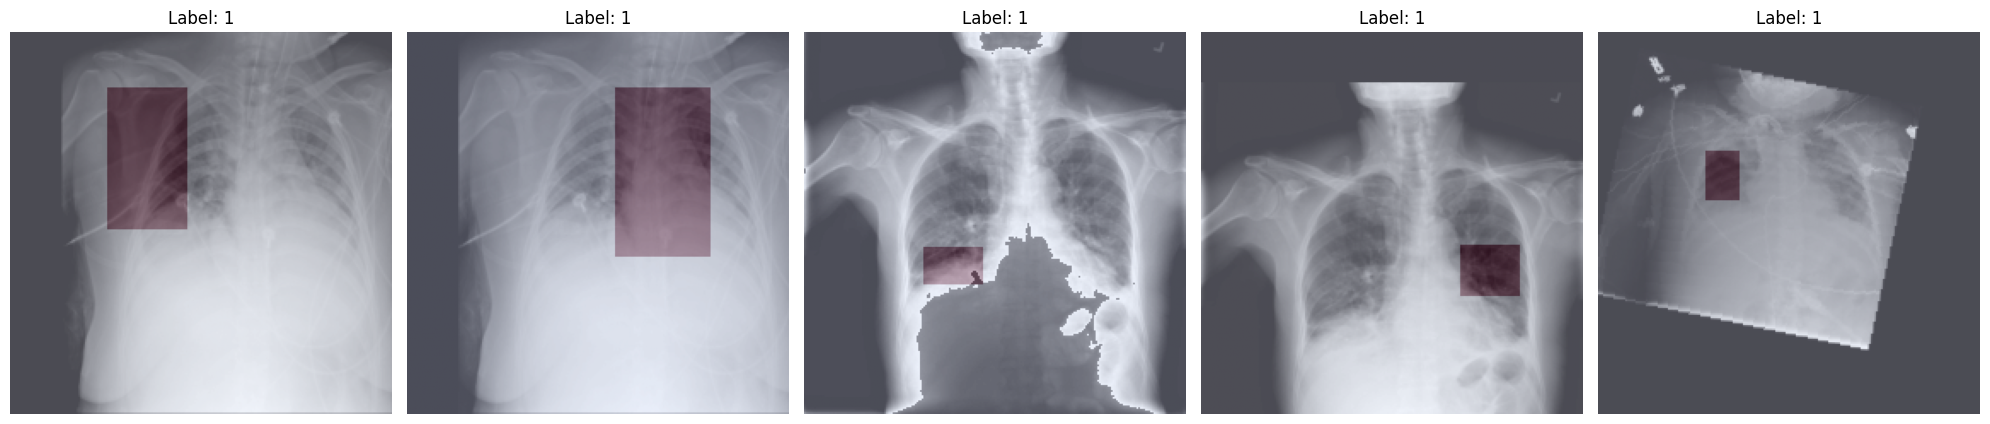

In [ ]:
import matplotlib.pyplot as plt
import torch

# 1. RSNA loader se ek batch uthayen
images, labels, masks = next(iter(rsna_loader))

# 2. Sirf Positive Samples (Label 1) filter karein
# (labels == 1) ek boolean tensor return karega, .nonzero() se humein indices mil jayenge
positive_indices = (labels == 1).nonzero(as_tuple=True)[0]

# Agar batch mein positive samples kam hon to sirf utne hi plot karein
to_plot = positive_indices[:5]
num_images = len(to_plot)

if num_images == 0:
    print("Is batch mein koi positive sample (label 1) nahi mila. Dubara run karein!")
else:
    fig, axes = plt.subplots(1, num_images, figsize=(20, 5))

    # Agar sirf 1 image ho to axes ko list mein convert karna zaroori hai
    if num_images == 1: axes = [axes]

    for i, idx in enumerate(to_plot):
        img = images[idx].permute(1, 2, 0).numpy()
        mask = masks[idx].squeeze().numpy()

        # Scaling for visualization
        img = (img - img.min()) / (img.max() - img.min())

        axes[i].imshow(img, cmap='gray')

        # Mask overlay (sirf agar mask available hai)
        if mask.sum() > 0:
            axes[i].imshow(mask, alpha=0.3, cmap='Reds')

        axes[i].set_title(f"Label: {labels[idx].item()}")
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.amp import GradScaler, autocast

# --- 1. Define Missing Functions ---
def cacr_loss(output, target, attn_map, mask, lambda_weight=1.0):
    cls_loss = F.cross_entropy(output, target)
    mask_small = F.interpolate(mask, size=(14, 14), mode='nearest')
    mask_small = mask_small.squeeze(1)
    attention_inside = (attn_map * mask_small).sum(dim=(1, 2))
    attention_total = attn_map.sum(dim=(1, 2))
    amil = (attention_inside / (attention_total + 1e-6)).mean()
    attn_loss = 1.0 - amil
    return cls_loss + (lambda_weight * attn_loss), cls_loss.item(), attn_loss.item()

def train_alignment_epoch(model, loader, optimizer, device, lambda_weight=1.0, accumulation_steps=8):
    model.train()
    total_loss, total_cls, total_attn = 0, 0, 0
    scaler = GradScaler('cuda')
    optimizer.zero_grad()

    storage = {'attn': None}
    def hook_fn(module, input, output):
        storage['attn'] = output.mean(dim=-1)[:, 1:].reshape(-1, 14, 14)

    hook = model.blocks[-1].attn.register_forward_hook(hook_fn)

    for i, (imgs, lbls, masks) in enumerate(loader):
        imgs, lbls, masks = imgs.to(device), lbls.to(device), masks.to(device)
        with autocast('cuda'):
            output = model(imgs)
            loss, cls_val, attn_val = cacr_loss(output, lbls, storage['attn'], masks, lambda_weight)
            loss = loss / accumulation_steps

        scaler.scale(loss).backward()
        if (i + 1) % accumulation_steps == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        total_loss += loss.item() * accumulation_steps
        total_cls += cls_val
        total_attn += attn_val

    hook.remove()
    return total_loss / len(loader), total_cls / len(loader), total_attn / len(loader)


# --- 2. Initialize a Fresh ViT for Ablation ---
print("🚀 Step 1: Initializing Fresh ViT for Ablation...")
vit_no_cacr = timm.create_model('vit_base_patch16_224', pretrained=True)
vit_no_cacr.head = nn.Linear(vit_no_cacr.head.in_features, 2)
vit_no_cacr = vit_no_cacr.to(device)

# --- 3. Stage 1: Pre-train on RSNA WITHOUT CACR (lambda = 0.0) ---
print("\n🔥 Stage 1: Pre-training on RSNA (NO CACR, Lambda=0.0)...")
optimizer_stage1 = torch.optim.AdamW(vit_no_cacr.parameters(), lr=1e-5)

for epoch in range(10):  # Adjust epochs if needed
    loss, cls_l, attn_l = train_alignment_epoch(
        vit_no_cacr, rsna_train_loader, optimizer_stage1, device,
        lambda_weight=0.0, accumulation_steps=8
    )
    print(f"RSNA Epoch {epoch+1} | CLS Loss: {cls_l:.4f} | Attn Loss (Ignored): {attn_l:.4f}")

# Save Stage 1 weights
torch.save(vit_no_cacr.state_dict(), "vit_rsna_nocacr_stage1.pth")
print("✅ RSNA No-CACR Weights Saved!")

# --- 4. Stage 2: Fine-tune on NIH (Standard Training) ---
print("\n🔥 Stage 2: Fine-tuning on NIH...")
optimizer_stage2 = torch.optim.AdamW(vit_no_cacr.parameters(), lr=1e-5)

for epoch in range(10): # Adjust epochs if needed
    loss, cls_l, attn_l = train_alignment_epoch(
        vit_no_cacr, nih_train_loader, optimizer_stage2, device,
        lambda_weight=0.0, accumulation_steps=8
    )
    print(f"NIH Epoch {epoch+1} | CLS Loss: {cls_l:.4f}")

torch.save(vit_no_cacr.state_dict(), "vit_rsna_nocacr_final.pth")

# --- 5. Stage 3: Test on CheXpert & Alignment Metrics ---
print("\n📊 Stage 3: Testing Ablation Model on CheXpert...")
vit_no_cacr.eval()
ablation_results = test_model(vit_no_cacr, chex_test_loader, device, mode="Test")

print("\n📊 Testing Ablation Model Alignment on RSNA...")
nocacr_amil, nocacr_iou = calculate_alignment_metrics(vit_no_cacr, rsna_test_loader, device)

print(f"\n📈 FINAL ABLATION RESULT (ViT + RSNA WITHOUT CACR)")
print(f"{'='*45}")
print(f"Baseline ViT AUROC:        0.5369")
print(f"Ablation ViT AUROC:        {ablation_results['auroc']:.4f}")
print(f"CACR Aligned ViT AUROC:    0.5726")
print(f"---")
print(f"Ablation ViT AMIL:         {nocacr_amil:.4f}")
print(f"Ablation ViT IoU:          {nocacr_iou:.4f}")
print(f"{'='*45}")

🚀 Step 1: Initializing Fresh ViT for Ablation...

🔥 Stage 1: Pre-training on RSNA (NO CACR, Lambda=0.0)...
RSNA Epoch 1 | CLS Loss: 0.5085 | Attn Loss (Ignored): 0.9596
RSNA Epoch 2 | CLS Loss: 0.4264 | Attn Loss (Ignored): 0.9599
RSNA Epoch 3 | CLS Loss: 0.3977 | Attn Loss (Ignored): 0.9600
RSNA Epoch 4 | CLS Loss: 0.3788 | Attn Loss (Ignored): 0.9601
RSNA Epoch 5 | CLS Loss: 0.3656 | Attn Loss (Ignored): 0.9598
RSNA Epoch 6 | CLS Loss: 0.3435 | Attn Loss (Ignored): 0.9601
RSNA Epoch 7 | CLS Loss: 0.3217 | Attn Loss (Ignored): 0.9598
RSNA Epoch 8 | CLS Loss: 0.2956 | Attn Loss (Ignored): 0.9596
RSNA Epoch 9 | CLS Loss: 0.2701 | Attn Loss (Ignored): 0.9594
RSNA Epoch 10 | CLS Loss: 0.2322 | Attn Loss (Ignored): 0.9592
✅ RSNA No-CACR Weights Saved!

🔥 Stage 2: Fine-tuning on NIH...
NIH Epoch 1 | CLS Loss: 0.5082
NIH Epoch 2 | CLS Loss: 0.4346
NIH Epoch 3 | CLS Loss: 0.4197
NIH Epoch 4 | CLS Loss: 0.4021
NIH Epoch 5 | CLS Loss: 0.3758
NIH Epoch 6 | CLS Loss: 0.3544
NIH Epoch 7 | CLS Loss

NameError: name 'get_auc_ci' is not defined

Creating Modelss

In [ ]:
import timm
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. NIH DenseNet121
nihdensenet = timm.create_model('densenet121', pretrained=True)
nihdensenet.classifier = nn.Linear(nihdensenet.classifier.in_features, 2)
nihdensenet = nihdensenet.to(device)

# 2. NIH ResNet50
nihresnet = timm.create_model('resnet50', pretrained=True)
nihresnet.fc = nn.Linear(nihresnet.fc.in_features, 2)
nihresnet = nihresnet.to(device)

# 3. NIH ViT (Vision Transformer)
nihvit = timm.create_model('vit_base_patch16_224', pretrained=True)
nihvit.head = nn.Linear(nihvit.head.in_features, 2)
nihvit = nihvit.to(device)


# 1. CheXpert DenseNet121
chexdensenet = timm.create_model('densenet121', pretrained=True)
chexdensenet.classifier = nn.Linear(chexdensenet.classifier.in_features, 2)
chexdensenet = chexdensenet.to(device)

# 2. CheXpert ResNet50
chexresnet = timm.create_model('resnet50', pretrained=True)
chexresnet.fc = nn.Linear(chexresnet.fc.in_features, 2)
chexresnet = chexresnet.to(device)

# 3. CheXpert ViT (Vision Transformer)
chexvit = timm.create_model('vit_base_patch16_224', pretrained=True)
chexvit.head = nn.Linear(chexvit.head.in_features, 2)
chexvit = chexvit.to(device)



print(f"✅ CheXpert models (chexdensenet, chexresnet, chexvit) initialized on {device}")
print(f"✅ All models (nihdensenet, nihresnet, nihvit) initialized on {device}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 32.3MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

✅ CheXpert models (chexdensenet, chexresnet, chexvit) initialized on cuda
✅ All models (nihdensenet, nihresnet, nihvit) initialized on cuda


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import confusion_matrix, roc_auc_score, f1_score
import numpy as np

# --- 1. GENERIC EVALUATION FUNCTION ---
def evaluate_metrics(all_labels, all_preds, all_probs):
    all_labels = np.array(all_labels)
    all_preds = np.array(all_preds)
    all_probs = np.array(all_probs)

    acc = (all_preds == all_labels).mean()
    tn, fp, fn, tp = confusion_matrix(all_labels, all_preds).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    f1 = f1_score(all_labels, all_preds)
    auroc = roc_auc_score(all_labels, all_probs)

    # Simple ECE calculation
    bin_boundaries = np.linspace(0, 1, 11)
    ece = 0
    for i in range(10):
        bin_idx = (all_probs > bin_boundaries[i]) & (all_probs <= bin_boundaries[i+1])
        if np.any(bin_idx):
            delta = np.abs(np.mean(all_probs[bin_idx]) - np.mean(all_labels[bin_idx]))
            ece += delta * (np.sum(bin_idx) / len(all_labels))

    return {
        "acc": acc, "auroc": auroc, "f1": f1,
        "sens": sensitivity, "spec": specificity, "ece": ece
    }

# --- 2. TRAINING FUNCTION ---
def train_model(model, model_name, train_loader, val_loader, device, epochs=5):
    print(f"🔥 Starting Training: {model_name}")
    criterion = nn.CrossEntropyLoss()

    # --- Conditional Optimizer Setup ---
    # Check if the name ends with 'vit' (case insensitive)
    if model_name.lower().endswith('vit'):
        print("🚀 [ViT Detected] Initializing AdamW + CosineAnnealingLR")
        optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5, weight_decay=1e-2)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    else:
        print("⚙️ [Standard Model] Initializing Adam Optimizer")
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
        scheduler = None

    best_val_auc = 0.0

    for epoch in range(epochs):
        model.train()
        train_loss = 0
        for imgs, lbls in train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, lbls)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        # Update Scheduler if it exists
        if scheduler:
            scheduler.step()

        # Har epoch ke baad validation check
        val_results = test_model(model, val_loader, device, mode="Validation")
        current_auc = val_results['auroc']

        print(f"Epoch [{epoch+1}/{epochs}] Loss: {train_loss/len(train_loader):.4f} | "
              f"Val Acc: {val_results['acc']:.3f} | Val AUROC: {current_auc:.3f}")

        # ✅ CHECKPOINT LOGIC
        if current_auc > best_val_auc:
            best_val_auc = current_auc
            torch.save(model.state_dict(), f"{model_name}.pth")
            print(f"⭐ New Best Model Saved with AUROC: {best_val_auc:.4f}")

    print(f"✅ Training Finished. Best AUROC achieved: {best_val_auc:.4f}")


# --- 3. TESTING / CROSS-DOMAIN FUNCTION ---
# --- 3. TESTING / CROSS-DOMAIN FUNCTION (Updated with CI) ---
def test_model(model, loader, device, mode="Test"):
    model.eval()
    all_labels, all_preds, all_probs = [], [], []

    with torch.no_grad():
        for imgs, lbls, masks in loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model(imgs)
            probs = F.softmax(outputs, dim=1)[:, 1]
            _, preds = torch.max(outputs, 1)

            all_labels.extend(lbls.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    # Standard metrics calculate karein
    results = evaluate_metrics(all_labels, all_preds, all_probs)

    if mode == "Test":
        print(f"\n {'='*10} {mode} Results {'='*10}")
        for k, v in results.items():
            print(f"{k.upper()}: {v:.4f}")

        # --- NEW: Confidence Interval Section ---
        labels_np = np.array(all_labels)
        probs_np = np.array(all_probs)

        # Function call karke range nikaalein
        lower, upper = get_auc_ci(labels_np, probs_np)

        print(f"✅ 95% Confidence Interval for AUROC: [{lower:.4f}, {upper:.4f}]")
        # Isay results dictionary mein save bhi kar sakte hain taake baad mein use ho sake
        results['auroc_ci'] = (lower, upper)

    return results



print("✅ Modular functions (train_model, test_model, evaluate_metrics) are ready!")

✅ Modular functions (train_model, test_model, evaluate_metrics) are ready!


NIH baselines (indomain)

In [ ]:
from sklearn.model_selection import train_test_split
import torch.optim as optim

# --- STEP 1: NIH Data Split (80% Train, 20% Val) ---
nih_train_df, nih_val_df = train_test_split(
    nih_df,
    test_size=0.2,
    random_state=42,
    stratify=nih_df['target']
)

# Naye DataLoaders sirf NIH training/validation ke liye
nih_train_loader = DataLoader(ChestXRayDataset(nih_train_df, nih_img_dir, transform=preprocess_transform),
                          batch_size=BATCH_SIZE, shuffle=True)
nih_test_loader = DataLoader(ChestXRayDataset(nih_val_df, nih_img_dir, transform=preprocess_transform),
                        batch_size=BATCH_SIZE, shuffle=False)



In [ ]:
# --- STEP 2: CheXpert Data Split (80% Train, 20% Test) ---
# Note: Isay hum mostly testing ke liye use karenge cross-domain check mein
chex_train_df, chex_test_df = train_test_split(
    chex_df,
    test_size=0.2,
    random_state=42,
    stratify=chex_df['target']
)

# --- STEP 3: CheXpert DataLoaders ---
# Training loader (sirf tab chahiye agar model ko Stanford pe train karna ho)
chex_train_loader = DataLoader(
    ChestXRayDataset(chex_train_df, chex_img_dir, transform=preprocess_transform),
    batch_size=BATCH_SIZE, shuffle=True
)

# Test loader (Hamara asli Cross-Domain benchmark)
chex_test_loader = DataLoader(
    ChestXRayDataset(chex_test_df, chex_img_dir, transform=preprocess_transform),
    batch_size=BATCH_SIZE, shuffle=False
)

print(f"✅ CheXpert Split Complete!")
print(f"📦 CheXpert Train Samples: {len(chex_train_df)}")
print(f"📦 CheXpert Test Samples:  {len(chex_test_df)}")

✅ CheXpert Split Complete!
📦 CheXpert Train Samples: 7740
📦 CheXpert Test Samples:  1935


In [ ]:
from sklearn.model_selection import train_test_split

# --- STEP 1: RSNA Data Split (80% Train, 20% Test) ---
# Ensure hum 'Target' column use kar rahe hain (as defined in your labels CSV)
rsna_train_df, rsna_test_df = train_test_split(
    rsna_df,
    test_size=0.2,
    random_state=42,
    stratify=rsna_df['Target']
)

# --- STEP 2: RSNA DataLoaders ---
# is_rsna=True zaruri hai taaki __getitem__ DICOM read kar sake
rsna_train_loader = DataLoader(
    ChestXRayDataset(rsna_train_df, rsna_img_dir, transform=preprocess_transform, is_rsna=True),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)

rsna_test_loader = DataLoader(
    ChestXRayDataset(rsna_test_df, rsna_img_dir, transform=preprocess_transform, is_rsna=True),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

print(f"✅ RSNA Split Complete!")
print(f"📦 RSNA Train Samples: {len(rsna_train_df)}")
print(f"📦 RSNA Test Samples:  {len(rsna_test_df)}")

# Sanity Check
images, labels, masks = next(iter(rsna_train_loader))
print(f"\n🔍 RSNA Batch Check:")
print(f"Image Shape: {images.shape}")
print(f"Mask Shape:  {masks.shape}") # Should be [BATCH_SIZE, 224, 224]

✅ RSNA Split Complete!
📦 RSNA Train Samples: 13244
📦 RSNA Test Samples:  3311

🔍 RSNA Batch Check:
Image Shape: torch.Size([32, 3, 224, 224])
Mask Shape:  torch.Size([32, 1, 224, 224])


In [ ]:
import os
import torch
import zipfile
import tempfile

def load_model_weights(model, weights_path, device):
    if not os.path.exists(weights_path):
        print(f"❌ Error: '{weights_path}' file nahi mili!")
        return None

    try:
        # 1. Direct load (Standard)
        state_dict = torch.load(weights_path, map_location=device)
        model.load_state_dict(state_dict)

    except Exception:
        # 2. Agar standard fail ho, toh zip/archive check karein
        try:
            with zipfile.ZipFile(weights_path, 'r') as zip_ref:
                with tempfile.TemporaryDirectory() as tmpdirname:
                    zip_ref.extractall(tmpdirname)
                    pkl_path = os.path.join(tmpdirname, 'chexresnet', 'data.pkl')

                    if os.path.exists(pkl_path):
                        state_dict = torch.load(pkl_path, map_location=device)
                        model.load_state_dict(state_dict)
                    else:
                        raise FileNotFoundError("data.pkl not found inside zip")
        except Exception as e:
            # Agar dono tarike fail ho jayein tabhi error print hoga
            print(f"❌ Failed: '{weights_path}' load nahi ho saki.")
            return None

    # Sab sahi hone par sirf ye print hoga
    model.to(device)
    print(f"✅ Success: '{weights_path}' loaded.")
    return model

In [ ]:
uewyfus

In [ ]:
#train_model(nihresnet, "nihresnet", nih_train_loader, nih_test_loader, device, epochs=10)
#load_model_weights(nihresnet, "nihresnet.pth", device)
#internal_results = test_model(nihresnet, nih_test_loader, device, mode="Test")

In [ ]:
cross_results = test_model(nihresnet, chex_test_loader, device, mode="Test")



 ========== Test Results ==========
ACC: 0.4884
AUROC: 0.5426
F1: 0.6474
SENS: 0.9722
SPEC: 0.0360
ECE: 0.0462


NameError: name 'get_auc_ci' is not defined

In [ ]:
import matplotlib.pyplot as plt
import torch
import cv2
import numpy as np

# Hook store karne ke liye list
attention_outputs = []

def get_attention_map(model, input_tensor):
    attention_outputs.clear() # Purana data saaf karo

    def hook_fn(module, input, output):
        # Kuch models mein output tuple hota hai, hume tensor chahiye
        # Check karo agar output list/tuple hai
        if isinstance(output, tuple):
            output = output[0]

        # Attention map extract karo
        # Timm ViT ke block mein attention weights aksar layer ke andar compute hote hain
        # Agar hook 'attn' layer par hai, toh woh output (projected features) dega
        # Lekin agar model mein raw attention weights chahiye, toh hume ensure karna hoga
        # ke hum sahi layer target kar rahe hain.

        # Let's try capturing the output of the attention layer itself
        attention_outputs.append(output.detach())

    # --- CHANGE: Hooking the attn layer ---
    # Timm ViT block structure: blocks[i].attn
    target_layer = model.blocks[-1].attn
    hook = target_layer.register_forward_hook(hook_fn)

    with torch.no_grad():
        model(input_tensor.unsqueeze(0).to(device))

    hook.remove()

    # Check if we got anything
    if not attention_outputs:
        print("❌ Hook didn't capture anything! Check layer path.")
        return None

    # Timm ViT mein attn output aksar [1, N, C] hota hai.
    # Agar tumhein raw attention matrix chahiye (N, N), toh
    # yeh hook simple layer output dega, weights nahi.
    # Lekin for visualization, aksar hum feature map use karte hain.
    return attention_outputs[0]

def visualize_attention(image, attn_map, original_img_size=(224, 224)):
    if attn_map is None:
        print("❌ Attention map is None, cannot visualize.")
        return

    # Visualizing 'projected features' as a proxy for attention
    # Agar attn_map [1, 197, 768] hai, toh hum mean lete hain across channels
    if len(attn_map.shape) == 3:
        attn_map = attn_map.mean(dim=-1) # Mean across embedding dimension

    # Remove CLS token (197 -> 196)
    attn_map = attn_map[0, 1:]

    # Reshape to 14x14
    num_patches = int(np.sqrt(attn_map.shape[-1]))
    attn_map = attn_map.reshape(num_patches, num_patches)

    # Normalize and Resize
    attn_map = attn_map.cpu().numpy()
    attn_map = (attn_map - attn_map.min()) / (attn_map.max() - attn_map.min())
    attn_map = cv2.resize(attn_map, original_img_size)

    # Overlay logic... (same as before)
    img_np = image.permute(1, 2, 0).cpu().numpy()
    img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min())

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_np)
    axes[0].set_title("Original X-Ray")
    axes[1].imshow(attn_map, cmap='jet')
    axes[1].set_title("Attention Heatmap")
    axes[2].imshow(img_np)
    axes[2].imshow(attn_map, cmap='jet', alpha=0.5)
    axes[2].set_title("Overlay")
    plt.show()



In [ ]:
#train_model(chexresnet, "chexresnet", chex_train_loader, chex_test_loader, device, epochs=10)
#load_model_weights(chexresnet, "chexresnet.pth", device)

In [ ]:
#with open('chexresnet.pth', 'rb') as f:
 #   print(f.read(100)) # File ke pehle 100 bytes print karein

In [ ]:
internal_result = test_model(chexresnet, chex_test_loader, device, mode="Test")

In [ ]:
#cross_results = test_model(chexresnet, nih_test_loader, device, mode="Test")

In [ ]:
#train_model(nihvit, "nihvit", nih_train_loader, nih_test_loader, device, epochs=10)
load_model_weights(nihvit, "nihvit.pth", device)

In [ ]:
internal_result = test_model(nihvit, nih_test_loader, device, mode="Test")

In [ ]:
#cross_results = test_model(nihvit, chex_test_loader, device, mode="Test")

In [ ]:
#train_model(chexvit, "chexvit", chex_train_loader, chex_test_loader, device, epochs=27)
load_model_weights(chexvit, "chexvit.pth", device)

In [ ]:
internal_result = test_model(chexvit, chex_test_loader, device, mode="Test")
# Convert lists to numpy arrays first
labels_np = np.array(all_labels)
probs_np = np.array(all_probs)

# Call the function
lower, upper = get_auc_ci(labels_np, probs_np)

print(f"✅ 95% Confidence Interval for AUROC: [{lower:.4f}, {upper:.4f}]")

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import cv2
import numpy as np

# Global storage for hook
attention_outputs = []

def get_attention_map(model, input_tensor):
    attention_outputs.clear()

    # 1. Device check
    input_tensor = input_tensor.to(device)

    # 2. DIMENSION CHECK:
    # Agar sirf single image hai [C, H, W], toh unsqueeze karo.
    # Agar batch hai [B, C, H, W], toh kuch mat karo!
    if input_tensor.ndim == 3:
        input_tensor = input_tensor.unsqueeze(0)

    def hook_fn(module, input, output):
        if isinstance(output, tuple): output = output[0]
        attention_outputs.append(output.detach())

    # Target the last attention block
    target_layer = model.blocks[-1].attn
    hook = target_layer.register_forward_hook(hook_fn)

    with torch.no_grad():
        model(input_tensor) # Ab unsqueeze hata diya hai

    hook.remove()
    return attention_outputs[0]

def visualize_attention_vs_mask(model, img, mask, model_name):
    model.eval()
    attn = get_attention_map(model, img)

    # Process Attention (Shape [1, 197, 768] -> Mean -> [14, 14])
    if len(attn.shape) == 3:
        attn = attn[0, 1:].mean(dim=-1) # Skip CLS, mean over features
    attn = attn.reshape(14, 14).detach().cpu().numpy()
    attn = cv2.resize(attn, (224, 224))
    attn = (attn - attn.min()) / (attn.max() - attn.min())

    # Image & Mask
    img_np = img.permute(1, 2, 0).cpu().numpy()
    img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min())
    mask_np = mask.squeeze().numpy()

    # Plot
    # 4. Plotting (The "Thesis Grade" Figure)
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # Left: Image + GT Mask
    axes[0].imshow(img_np)
    axes[0].imshow(mask_np, cmap='Reds', alpha=0.4)
    axes[0].set_title("Ground Truth (Mask)")
    axes[0].axis('off')

    # Middle: Image + Attention
    axes[1].imshow(img_np)
    axes[1].imshow(attn, cmap='jet', alpha=0.5)
    axes[1].set_title("ViT Attention Map")
    axes[1].axis('off')

    # --- RIGHT: FIXED OVERLAY ---
    # Convert image to uint8 copy explicitly first
    canvas = (img_np * 255).astype(np.uint8).copy()

    # Find contours
    contours, _ = cv2.findContours((mask_np*255).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    # Draw on the persistent canvas variable
    cv2.drawContours(canvas, contours, -1, (0, 255, 0), 2)

# --- RIGHT: FIXED OVERLAY ---
    axes[2].imshow(img_np) # Base image
    axes[2].imshow(attn, cmap='jet', alpha=0.4) # Attention Overlay

    # Thesis-grade outline (Better than cv2.drawContours for plotting)
    # Hum directly mask ke contours plot kar rahe hain
    axes[2].contour(mask_np, colors='red', linewidths=2, levels=[0.5])

    axes[2].set_title("Alignment (Ground Truth vs Attention)")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

print("✅ Setup Ready!")

In [ ]:
cross_results = test_model(chexvit, nih_test_loader, device, mode="Test")

In [ ]:
#train_model(chexdensenet, "chexdensenet", chex_train_loader, chex_test_loader, device, epochs=10)

In [ ]:
#internal_result = test_model(chexdensenet, chex_test_loader, device, mode="Test")

In [ ]:
#cross_results = test_model(chexdensenet, nih_test_loader, device, mode="Test")

In [ ]:
#train_model(nihdensenet, "nihdensenet", nih_train_loader, nih_test_loader, device, epochs=10)

In [ ]:
#internal_result = test_model(nihdensenet, nih_test_loader, device, mode="Test")

In [ ]:
#cross_results = test_model(nihdensenet, chex_test_loader, device, mode="Test")

In [ ]:
# 1011 number ki image access karo (0-indexed hota hai, toh 1011 likho)
idx = 777
sample_img, label, mask = nih_dataset[idx]

# NIH-ViT Visualization
print(f"🔍 Visualizing NIH-ViT for Index {idx}...")
attn_matrix = get_attention_map( chexvit, sample_img)
visualize_attention(sample_img, attn_matrix)
plt.suptitle(f"Model: NIH-ViT | Image Index: {idx}", fontsize=14)
plt.show()

In [ ]:
# 1. CheXpert-ViT Visualization
print("🔍 Processing CheXpert-ViT Focus...")
chexvit.eval()

# Attention extract karo
attn_matrix_chex = get_attention_map(chexvit, sample_img)

# Visualize karo
visualize_attention(sample_img, attn_matrix_chex)
plt.suptitle("Model: CheXpert-ViT (Target Domain)", fontsize=14)
plt.show()

In [ ]:
rsna_result2 = test_model(nihvit, rsna_test_loader, device, mode="Test")

In [ ]:
rsna_result1 = test_model(chexvit, rsna_test_loader, device, mode="Test")

In [ ]:
# 1. Loader se ek batch uthao
images, labels, masks = next(iter(rsna_loader))

# 2. Positive (Pneumonia) indices dhoondo
positive_indices = (labels == 1).nonzero(as_tuple=True)[0]

if len(positive_indices) > 0:
    # 3. Pehla positive sample uthao
    idx = positive_indices[0]
    img = images[idx]
    label = labels[idx]
    mask = masks[idx]

    # 4. Visualize
    visualize_attention_vs_mask(nihvit, img, mask, "NIH-ViT")
else:
    print("Is batch mein koi pneumonia sample nahi mila. Loader se agla batch uthao!")

In [ ]:
# 1. Loader se ek batch uthao
images, labels, masks = next(iter(rsna_loader))

# 2. Positive (Pneumonia) indices dhoondo
positive_indices = (labels == 1).nonzero(as_tuple=True)[0]

if len(positive_indices) > 0:
    # 3. Pehla positive sample uthao
    idx = positive_indices[0]
    img = images[idx]
    label = labels[idx]
    mask = masks[idx]

    # 4. Visualize
    visualize_attention_vs_mask(chexvit, img, mask, "CHEX-ViT")
else:
    print("Is batch mein koi pneumonia sample nahi mila. Loader se agla batch uthao!")

In [ ]:
import torch.nn.functional as F

def calculate_alignment_metrics(model, loader, device):
    model.eval()
    all_amils = []
    all_ious = []

    with torch.no_grad():
        for imgs, lbls, masks in loader:
            imgs, masks = imgs.to(device), masks.to(device)

                        # 1. Get Attention
                        # (Assuming get_attention_map returns [B, 1, 14, 14])
                        # Inside calculate_alignment_metrics loop:
            attn = get_attention_map(model, imgs) # Returns [B, 197, 768] (with CLS token)
            attn = attn[:, 1:, :]                 # Remove CLS token -> [B, 196, 768]
            attn = attn.mean(dim=-1)              # Average features -> [B, 196]
            attn = attn.view(imgs.shape[0], 1, 14, 14) # Reshape to [B, 1, 14, 14]

            # Ab yeh "attn" upsample ke liye ready hai!


            # 2. Resize Attention to match Mask (224x224)
            attn_upsampled = F.interpolate(attn, size=(224, 224), mode='bilinear', align_corners=False)
            attn_upsampled = (attn_upsampled - attn_upsampled.min()) / (attn_upsampled.max() - attn_upsampled.min() + 1e-6)

            # 3. Calculate AMIL
            # Formula: Sum(Attn * Mask) / Sum(Attn)
            amil = (attn_upsampled * masks).sum() / (attn_upsampled.sum() + 1e-6)
            all_amils.append(amil.item())

            # 4. Calculate IoU
            # Thresholding attention to binary (using mean as dynamic threshold)
            threshold = attn_upsampled.mean()
            attn_bin = (attn_upsampled > threshold).float()

            intersection = (attn_bin * masks).sum()
            union = (attn_bin + masks).clamp(0, 1).sum()
            iou = intersection / (union + 1e-6)
            all_ious.append(iou.item())

    return np.mean(all_amils), np.mean(all_ious)

In [ ]:
print("📊 Testing NIH-ViT Alignment...")
nih_amil, nih_iou = calculate_alignment_metrics(nihvit, rsna_test_loader, device)
print(f"NIH-ViT | AMIL: {nih_amil:.4f} | IoU: {nih_iou:.4f}")

In [ ]:
print("📊 Testing CHEX-ViT Alignment...")
nih_amil, nih_iou = calculate_alignment_metrics(chexvit, rsna_test_loader, device)
print(f"CHEX-ViT | AMIL: {nih_amil:.4f} | IoU: {nih_iou:.4f}")

AIML P4

In [ ]:
from torch.utils.data import DataLoader

# --- 1. Configuration ---
BATCH_SIZE = 8
NUM_WORKERS = 2  # Background mein data load karne ke liye cores

# --- 2. Create DataLoaders ---

# NIH (Source Hospital - Training ke liye)
# Isay shuffle karna zaroori hai
nih_loader = DataLoader(
    nih_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)

# CheXpert (Target Hospital - Testing ke liye)
# Isay shuffle karne ki zaroori nahi
chex_loader = DataLoader(
    chexpert_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

# RSNA (Clinical Alignment - Alignment Phase ke liye)
rsna_loader = DataLoader(
    rsna_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

print(f"✅ DataLoaders Ready!")
print(f"📦 NIH Batches:      {len(nih_loader)}")
print(f"📦 CheXpert Batches: {len(chex_loader)}")
print(f"📦 RSNA Batches:     {len(rsna_loader)}")

# --- 3. Simple Sanity Check ---
# Check if one batch loads correctly
images, labels,_ = next(iter(nih_loader))
print(f"\n🔍 Sanity Check (NIH Batch):")
print(f"Image Batch Shape: {images.shape}") # Expecting [32, 3, 224, 224]
print(f"Label Batch Shape: {labels.shape}") # Expecting [32]

In [ ]:
from torch.utils.data import DataLoader

# --- 1. Path Configuration ---
# Apne folders ke mutabiq inhein verify karlein
nih_img_dir = 'nih_data/images-224/images-224'
chex_img_dir = 'chexpert_data/'  # CheXpert paths CSV ke andar already detailed hain
rsna_img_dir = 'rsna_data/stage_2_train_images'

# --- 2. Initialize Datasets ---

# NIH (Source Hospital)
nih_dataset = ChestXRayDataset(nih_df, nih_img_dir, transform=preprocess_transform)

# CheXpert (Target Hospital - Cross Hospital Test)
chexpert_dataset = ChestXRayDataset(chex_df, chex_img_dir, transform=preprocess_transform)

# RSNA (Clinical Alignment - Ground Truth Boxes)
rsna_dataset = ChestXRayDataset(rsna_df, rsna_img_dir, transform=preprocess_transform, is_rsna=True)

print(f"✅ NIH Dataset initialized:      {len(nih_dataset)} images")
print(f"✅ CheXpert Dataset initialized: {len(chexpert_dataset)} images")
print(f"✅ RSNA Dataset initialized:     {len(rsna_dataset)} images")

In [ ]:
from sklearn.model_selection import train_test_split

# --- STEP 1: RSNA Data Split (80% Train, 20% Test) ---
# Ensure hum 'Target' column use kar rahe hain (as defined in your labels CSV)
rsna_train_df, rsna_test_df = train_test_split(
    rsna_df,
    test_size=0.2,
    random_state=42,
    stratify=rsna_df['Target']
)

# --- STEP 2: RSNA DataLoaders ---
# is_rsna=True zaruri hai taaki __getitem__ DICOM read kar sake
rsna_train_loader = DataLoader(
    ChestXRayDataset(rsna_train_df, rsna_img_dir, transform=preprocess_transform, is_rsna=True),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS
)

rsna_test_loader = DataLoader(
    ChestXRayDataset(rsna_test_df, rsna_img_dir, transform=preprocess_transform, is_rsna=True),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS
)

print(f"✅ RSNA Split Complete!")
print(f"📦 RSNA Train Samples: {len(rsna_train_df)}")
print(f"📦 RSNA Test Samples:  {len(rsna_test_df)}")

# Sanity Check
images, labels, masks = next(iter(rsna_train_loader))
print(f"\n🔍 RSNA Batch Check:")
print(f"Image Shape: {images.shape}")
print(f"Mask Shape:  {masks.shape}") # Should be [BATCH_SIZE, 224, 224]

In [ ]:
import torch.nn.functional as F

def cacr_loss(output, target, attn_map, mask, lambda_weight=1.0):
    """
    attn_map: [Batch, 14, 14] - raw attention from ViT
    mask: [Batch, 1, 224, 224] - RSNA bounding box mask
    """
    # 1. Standard Cross Entropy (Classification)
    cls_loss = F.cross_entropy(output, target)

    # 2. Resize mask to match attn_map (14x14)
    mask_small = F.interpolate(mask, size=(14, 14), mode='nearest')
    mask_small = mask_small.squeeze(1) # [Batch, 14, 14]

    # 3. AMIL (Attention Mass Inside Lesion)
    # attn_map aur mask_small multiply karo (donon 14x14 hain)
    attention_inside = (attn_map * mask_small).sum(dim=(1, 2))
    attention_total = attn_map.sum(dim=(1, 2))

    # AMIL calculate karo (Batch wise mean)
    amil = (attention_inside / (attention_total + 1e-6)).mean()

    # 4. Attention Loss (1 - AMIL)
    # Hum chahte hain AMIL 1.0 ke kareeb ho, isliye loss ko minimize kar rahe hain
    attn_loss = 1.0 - amil

    return cls_loss + (lambda_weight * attn_loss), cls_loss.item(), attn_loss.item()

In [ ]:
from torch.amp import GradScaler, autocast

def train_alignment_epoch(model, loader, optimizer, device, lambda_weight=1.0, accumulation_steps=8):
    model.train()
    total_loss, total_cls, total_attn = 0, 0, 0
    scaler = GradScaler('cuda')
    optimizer.zero_grad() # Initialize gradients

    storage = {'attn': None}
    def hook_fn(module, input, output):
        # We capture features from the attn layer to compute heatmap
        storage['attn'] = output.mean(dim=-1)[:, 1:].reshape(-1, 14, 14)

    hook = model.blocks[-1].attn.register_forward_hook(hook_fn)

    for i, (imgs, lbls, masks) in enumerate(loader):
        imgs, lbls, masks = imgs.to(device), lbls.to(device), masks.to(device)

        # 1. Forward pass with AMP
        with autocast('cuda'):
            output = model(imgs)
            loss, cls_val, attn_val = cacr_loss(output, lbls, storage['attn'], masks, lambda_weight)
            # Normalize loss by accumulation steps
            loss = loss / accumulation_steps

        # 2. Scaled backward pass
        scaler.scale(loss).backward()

        # 3. Update weights only every N steps
        if (i + 1) % accumulation_steps == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        total_loss += loss.item() * accumulation_steps
        total_cls += cls_val
        total_attn += attn_val

    hook.remove()
    return total_loss / len(loader), total_cls / len(loader), total_attn / len(loader)



In [ ]:
# --- CONFIG ---
BATCH_SIZE = 4 # Keep this low!
optimizer = torch.optim.AdamW(nihvit.parameters(), lr=1e-5)

print("🚀 Starting Alignment Training with Gradient Accumulation...")
# Run for a few epochs
for epoch in range(10):
    loss, cls_l, attn_l = train_alignment_epoch(nihvit, rsna_train_loader, optimizer, device, accumulation_steps=8)
    print(f"Epoch {epoch+1}: Total Loss: {loss:.4f} | CLS Loss: {cls_l:.4f} | Attn Loss: {attn_l:.4f}")

In [ ]:
torch.save(nihvit.state_dict(), "nihvit_a_rsna.pth")
print("✅ Aligned Model Saved!")

In [ ]:


# 1. Loader se ek batch uthao
images, labels, masks = next(iter(rsna_loader))

# 2. Positive (Pneumonia) indices dhoondo
positive_indices = (labels == 1).nonzero(as_tuple=True)[0]

if len(positive_indices) > 0:
    # 3. Pehla positive sample uthao
    idx = positive_indices[0]
    img = images[idx]
    label = labels[idx]
    mask = masks[idx]

    # 4. Visualize
    visualize_attention_vs_mask(nihvit, img, mask, "NIH-ViT")
else:
    print("Is batch mein koi pneumonia sample nahi mila. Loader se agla batch uthao!")

In [ ]:
print("📊 Testing Aligned Model (nihvit_aligned) on CheXpert (Cross-Domain)...")
nihvit.eval()

# Hum apna standard test function use karenge jo upar defined hai
aligned_cross_results = test_model(nihvit, chex_test_loader, device, mode="Test")

print(f"\n📈 RESULTS COMPARISON (NIH -> CheXpert)")
print(f"{'='*40}")
print(f"Baseline ViT AUROC: 0.5369")
print(f"Aligned ViT AUROC:  {aligned_cross_results['auroc']:.4f}")
print(f"{'='*40}")

if aligned_cross_results['auroc'] > 0.5369:
    print(f"🔥 SUCCESS: Alignment improved cross-domain robustness by {aligned_cross_results['auroc'] - 0.5369:.4f}!")
else:
    print("⚠️ Accuracy stagnant. Needs final fine-tuning phase to recalibrate.")

In [ ]:
# Baseline load karne ke liye
nihvit_baseline = timm.create_model('vit_base_patch16_224', pretrained=True)
nihvit_baseline.head = nn.Linear(nihvit_baseline.head.in_features, 2)
load_model_weights(nihvit_baseline, "nihvit.pth", device) # Aapka purana filename
print("✅ Baseline NIH-ViT Reloaded for comparison!")

In [ ]:
# Baseline load karne ke liye
nihvit_baseline = timm.create_model('vit_base_patch16_224', pretrained=True)
nihvit_baseline.head = nn.Linear(nihvit_baseline.head.in_features, 2)
load_model_weights(nihvit_baseline, "nihvit.pth", device) # Aapka purana filename
print("✅ Baseline NIH-ViT Reloaded for comparison!")

In [ ]:
# 1. Model architecture define karein
chexvit_baseline = timm.create_model('vit_base_patch16_224', pretrained=True)
chexvit_baseline.head = nn.Linear(chexvit_baseline.head.in_features, 2)

# 2. Purane weights load karein (Jo aapne Phase 1/2 mein save kiye thay)
# Note: Agar aapka file name different hai (e.g., 'chexvit_best.pth'), toh wo likhein
load_model_weights(chexvit_baseline, "chexvit.pth", device)

In [ ]:
images, labels, masks = next(iter(rsna_test_loader))
positive_indices = (labels == 1).nonzero(as_tuple=True)[0]

for i in positive_indices:
    # Assuming you want to print the integer value of each index
    print(i.item())

In [ ]:
# --- Thesis Grade Visualization Cell ---

# 1. RSNA test loader se positive sample (pneumonia present) dhoondo
images, labels, masks = next(iter(rsna_test_loader))
positive_indices = (labels == 1).nonzero(as_tuple=True)[0]

if len(positive_indices) > 0:
    # Batch ka pehla pneumonia sample pick karo
    idx = 7
    img = images[idx]
    mask = masks[idx]

    print(f"✅ Found Pneumonia Positive Sample at Batch Index: {idx}")
    print("-" * 30)

    # 2. Baseline Models vs Aligned Model Comparison
    # Hum bari-bari aapka visualize function call karenge different models ke liye

    print("📈 Generating Comparison Grid...")

    # Section A: Baseline NIH-ViT (Shortcut Learner)
    print("Visualizing Baseline NIH-ViT...")
    visualize_attention_vs_mask(nihvit_baseline, img, mask, "Baseline NIH-ViT")

    # Section B: Baseline CheX-ViT (Artifact Focused)
    print("Visualizing Baseline CheX-ViT...")
    visualize_attention_vs_mask(chexvit_baseline, img, mask, "Baseline CheX-ViT")

    # Section C: CACR Aligned NIH-ViT (Aapka Naya Hero Model)
    print("Visualizing Aligned NIH-ViT (Ours)...")
    # Note: 'nihvit' yahan aapka naya train kiya hua aligned model hona chahiye
    visualize_attention_vs_mask(nihvit, img, mask, "CACR Aligned NIH-ViT")

else:
    print("❌ Is batch mein koi pneumonia sample nahi mila. Loader dobara run karein.")

In [ ]:
print("📊 Testing NIH-ViT Alignment...")
nih_amil, nih_iou = calculate_alignment_metrics(nihvit, rsna_test_loader, device)
print(f"NIH-ViT | AMIL: {nih_amil:.4f} | IoU: {nih_iou:.4f}")

In [ ]:
# Simple way to get 95% Confidence Interval for AUROC
import numpy as np
from sklearn.utils import resample

def get_auc_ci(labels, probs, n_bootstraps=1000):
    bootstrapped_scores = []
    for _ in range(n_bootstraps):
        # Bootstrap sample
        indices = np.random.randint(0, len(probs), len(probs))
        if len(np.unique(labels[indices])) < 2: continue
        score = roc_auc_score(labels[indices], probs[indices])
        bootstrapped_scores.append(score)

    sorted_scores = np.array(bootstrapped_scores)
    sorted_scores.sort()
    return sorted_scores[int(0.025 * len(sorted_scores))], sorted_scores[int(0.975 * len(sorted_scores))]



In [ ]:
# 1. Aligned model ko eval mode mein karein
nihvit.eval()

# 2. Test Model call karein (Ismein humne CI wala logic abhi add kiya hai)
print("📊 Testing CACR Aligned Model on CheXpert with Statistical Validation...")
final_results = test_model(nihvit, chex_test_loader, device, mode="Test")

# 3. Specific formatting for your report
lower, upper = final_results['auroc_ci']
print(f"\n📝 Report Notation: AUROC = {final_results['auroc']:.4f} (95% CI: {lower:.4f} - {upper:.4f})")

## Dataset Sources and Preprocessing

This project utilizes three publicly available chest X-ray datasets: NIH Chest X-ray 14, CheXpert, and RSNA Pneumonia Detection Challenge. Each dataset underwent specific preprocessing steps to prepare them for model training and evaluation.

### 1. NIH Chest X-ray 14 Dataset

-   **Source**: Kaggle dataset: `khanfashee/nih-chest-x-ray-14-224x224-resized`.
-   **Original Metadata**: `Data_Entry_2017.csv`.
-   **Preprocessing Steps**:
    1.  **Label Filtering**: Images were filtered to include only those labeled with 'Pneumonia' or 'No Finding'. Entries with multi-labels containing 'Pneumonia' (e.g., 'Pneumonia|Infiltration') were considered positive for Pneumonia.
    2.  **Class Balancing**: A subsample was created with a 1:3 ratio of 'Pneumonia' positive cases to 'No Finding' (normal) cases. All 'Pneumonia' cases were included, and 'No Finding' cases were randomly sampled to achieve this ratio.
    3.  **Target Column**: A binary `target` column was created where `1` indicates 'Pneumonia' and `0` indicates 'No Finding'.
    4.  **Data Shuffling**: The combined dataset was shuffled to ensure randomness.
    5.  **Image Scrubbing**: Each image path was verified for existence and integrity using `PIL.Image.verify()` to remove any broken or missing image files.

### 2. CheXpert Dataset

-   **Source**: Kaggle dataset: `mimsadiislam/chexpert`.
-   **Original Metadata**: `train.csv` (from `CheXpert-v1.0-small` directory).
-   **Preprocessing Steps**:
    1.  **Label Interpretation**: For the 'Pneumonia' column, `1.0` was treated as positive, and `0.0` or `-1.0` (uncertain) were conservatively treated as negative (`0`).
    2.  **View Filtering**: Only 'Frontal' view X-rays were retained to ensure consistency with other datasets.
    3.  **Class Balancing**: All 'Pneumonia' positive frontal cases were included. From the remaining negative frontal cases, 5,000 images were randomly sampled to create a balanced subset.
    4.  **Target Column**: A binary `target` column was created based on the interpreted 'Pneumonia' label (`1` for Pneumonia, `0` for Normal/Other).
    5.  **Data Shuffling**: The combined dataset was shuffled.
    6.  **Image Scrubbing**: Image paths were verified for existence and `PIL.Image.verify()` was used to check image integrity.

### 3. RSNA Pneumonia Detection Challenge Dataset

-   **Source**: Kaggle competition: `rsna-pneumonia-detection-challenge`.
-   **Original Metadata**: `stage_2_train_labels.csv` (contains patient IDs and bounding box coordinates for pneumonia).
-   **Preprocessing Steps**:
    1.  **Label Loading**: The `stage_2_train_labels.csv` file was loaded, which provides `patientId` and `Target` (1 for Pneumonia, 0 for Normal).
    2.  **DICOM Handling**: Images are in DICOM format, requiring the `pydicom` library for loading and processing.
    3.  **Patient-Level Balancing**: Unique `patientId`s were extracted to ensure each patient is counted once for balancing. All patients with 'Pneumonia' (`Target == 1`) were included. From the normal patients (`Target == 0`), 7,000 unique patients were randomly sampled.
    4.  **Dataset Filtering**: The original `rsna_df` was then filtered to retain only the images corresponding to the selected balanced set of unique patients.
    5.  **Bounding Box Information**: For 'Pneumonia' cases, bounding box coordinates (`x`, `y`, `width`, `height`) are available, which are used to generate ground truth masks for model alignment evaluation.

### Common Preprocessing for Model Input

All images, regardless of their source, were processed through a unified transformation pipeline for input into the neural networks:

-   **Resizing**: Images were resized to `(224, 224)` pixels.
-   **Data Augmentation**: `RandAugment` was applied with `num_ops=2` and `magnitude=9` for increased data variability and model robustness.
-   **Tensor Conversion**: Images were converted to PyTorch tensors.
-   **Normalization**: Pixel values were normalized using the standard ImageNet mean `[0.485, 0.456, 0.406]` and standard deviation `[0.229, 0.224, 0.225]`.

### `ChestXRayDataset` Class

A custom `ChestXRayDataset` class was implemented to handle the specific loading requirements of each dataset:

-   It differentiates between RSNA (DICOM files) and NIH/CheXpert (standard image files).
-   It applies the `preprocess_transform` to all images.
-   For RSNA, it additionally generates a `mask` tensor (224x224) from the bounding box information for 'Pneumonia' cases, representing the ground truth lesion area. This mask is used specifically for calculating alignment metrics (AMIL, IoU) and during the alignment training phase.